Rows shared by train and test: 0
Train: (8000, 14) Test: (2000, 14)
Encoded features: 78


/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encounter


--- Multinomial NB (best alpha = 5.0) ---
[[1539  295]
 [   3  163]]
              precision    recall  f1-score   support

           0      0.998     0.839     0.912      1834
           1      0.356     0.982     0.522       166

    accuracy                          0.851      2000
   macro avg      0.677     0.911     0.717      2000
weighted avg      0.945     0.851     0.879      2000

ROC AUC: 0.962 | PR AUC: 0.682

--- Bernoulli NB (best alpha = 5.0) ---
[[1539  295]
 [   3  163]]
              precision    recall  f1-score   support

           0      0.998     0.839     0.912      1834
           1      0.356     0.982     0.522       166

    accuracy                          0.851      2000
   macro avg      0.677     0.911     0.717      2000
weighted avg      0.945     0.851     0.879      2000

ROC AUC: 0.962 | PR AUC: 0.681
Baseline PR AUC (fraud rate): 0.083

Top values pointing toward fraud:
Service_Claim_days_(-1.001, 2.0]      2.51
Claim_Amount_(1500.0, inf]      

/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encounter

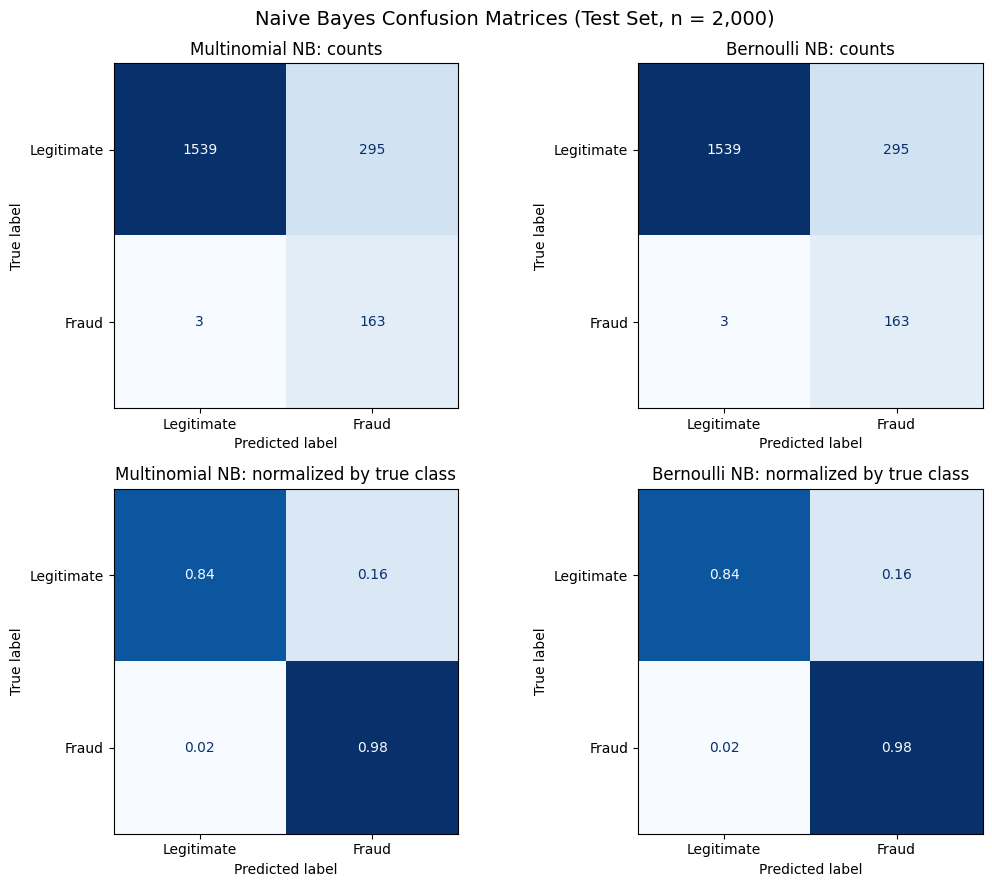

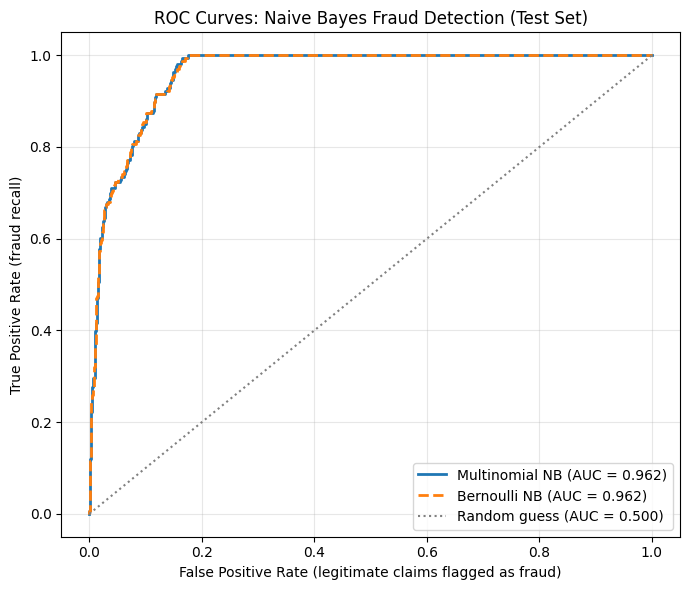

In [15]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

df = pd.read_csv('health_data.csv')

label = 'Is_Fraud'
num_cols = ['Claim_Amount', 'Patient_Age', 'No_of_Claims_Provider',
            'Service_Claim_days', 'Length_of_Stay', 'Prior_Visits_12m',
            'Chronic_Condition_Flag']
cat_cols = ['Insurance_Type', 'Patient_Gender', 'Provider_Specialty', 'Visit_Type',
            'State', 'Diagnosis_Code', 'Procedure_Code']

X_raw = df[num_cols + cat_cols].copy()
y = df[label]

X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_test = X_train.copy(), X_test.copy()
print("Rows shared by train and test:", len(set(X_train.index) & set(X_test.index)))  # must be 0
print("Train:", X_train.shape, "Test:", X_test.shape)

"""Fill missing values using training-set statistics only (to avoid leakage), 
then define the bin edges that convert continuous columns into ranges so Naive Bayes can use them as categories."""

for d in (X_train, X_test):
    d['Provider_Specialty'] = d['Provider_Specialty'].fillna('Unknown')
prior_median = X_train['Prior_Visits_12m'].median()
for d in (X_train, X_test):
    d['Prior_Visits_12m'] = d['Prior_Visits_12m'].fillna(prior_median)


bins = {
    'Claim_Amount':          [0, 300, 500, 700, 1000, 1500, np.inf],
    'Patient_Age':           [-1, 18, 35, 50, 64, 120],
    'No_of_Claims_Provider': [0, 55, 65, 75, 100, np.inf],
    'Service_Claim_days':    [-1, 2, 4, 6, 10, 20, 30],
    'Prior_Visits_12m':      [-1, 1, 2, 3, 5, np.inf],
}
for col, edges in bins.items():
    for d in (X_train, X_test):
        d[col] = pd.cut(d[col], edges, include_lowest=True).astype(object)
        # Values outside the bins become an explicit category instead of a silent "nan"
        d[col] = d[col].where(d[col].notna(), 'Out_of_range')
    n_out = (X_train[col] == 'Out_of_range').sum() + (X_test[col] == 'Out_of_range').sum()
    if n_out > 0:
        print(f"WARNING: {n_out} values in {col} fall outside the bins")


min_count = 30
for col in ['State', 'Diagnosis_Code', 'Procedure_Code']:
    counts = X_train[col].astype(str).value_counts()
    keep = set(counts[counts >= min_count].index)
    for d in (X_train, X_test):
        d[col] = d[col].astype(str).where(d[col].astype(str).isin(keep), 'Other')


X_train_oh = pd.get_dummies(X_train.astype(str), dtype=int)
X_test_oh = pd.get_dummies(X_test.astype(str), dtype=int).reindex(
    columns=X_train_oh.columns, fill_value=0)
print("Encoded features:", X_train_oh.shape[1])


train_out = X_train_oh.copy(); train_out['Is_Fraud'] = y_train
test_out = X_test_oh.copy();   test_out['Is_Fraud'] = y_test
train_out.to_csv('nb_training_set.csv', index=False)
test_out.to_csv('nb_testing_set.csv', index=False)
pd.concat([train_out, test_out]).to_csv('nb_prepared_data.csv', index=False)

"""Modeling fitting and validation"""
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
param_grid = {'alpha': [0.1, 0.5, 1.0, 2.0, 5.0]}

def fit_nb(model, name):
    gs = GridSearchCV(model, param_grid, cv=cv, scoring='average_precision')
    gs.fit(X_train_oh, y_train)
    best = gs.best_estimator_
    pred = best.predict(X_test_oh)
    prob = best.predict_proba(X_test_oh)[:, 1]
    print(f"\n--- {name} (best alpha = {gs.best_params_['alpha']}) ---")
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, digits=3))
    roc = roc_auc_score(y_test, prob)
    pr = average_precision_score(y_test, prob)
    print("ROC AUC:", round(roc, 3), "| PR AUC:", round(pr, 3))
    return best, pred, prob, roc, pr


mnb, mnb_pred, mnb_prob, mnb_roc, mnb_pr = fit_nb(MultinomialNB(fit_prior=False), "Multinomial NB")
bnb, bnb_pred, bnb_prob, bnb_roc, bnb_pr = fit_nb(BernoulliNB(fit_prior=False), "Bernoulli NB")
print("Baseline PR AUC (fraud rate):", round(y_test.mean(), 3))


log_ratio = pd.Series(mnb.feature_log_prob_[1] - mnb.feature_log_prob_[0],
                      index=X_train_oh.columns)
support = X_train_oh.sum()                 # training rows where the value is present
reliable = log_ratio[support >= min_count] # ignore very rare values
print("\nTop values pointing toward fraud:")
print(reliable.sort_values(ascending=False).head(8).round(2))
print("\nTop values pointing toward not fraud:")
print(reliable.sort_values().head(8).round(2))


models = [("Multinomial NB", mnb_pred), ("Bernoulli NB", bnb_pred)]
class_names = ["Legitimate", "Fraud"]

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

"""Displaying the confusion matrix"""
for i, (name, pred) in enumerate(models):
   
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=class_names,
        cmap="Blues", values_format="d", ax=axes[0, i], colorbar=False)
    axes[0, i].set_title(f"{name}: counts")


    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=class_names, normalize="true",
        cmap="Blues", values_format=".2f", ax=axes[1, i], colorbar=False)
    axes[1, i].set_title(f"{name}: normalized by true class")

plt.suptitle("Naive Bayes Confusion Matrices (Test Set, n = 2,000)", fontsize=14)
plt.tight_layout()
plt.savefig("nb_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

"""Plotting ROC Curves"""
fpr_m, tpr_m, _ = roc_curve(y_test, mnb_prob)
fpr_b, tpr_b, _ = roc_curve(y_test, bnb_prob)

plt.figure(figsize=(7, 6))
plt.plot(fpr_m, tpr_m, lw=2, label=f"Multinomial NB (AUC = {mnb_roc:.3f})")
plt.plot(fpr_b, tpr_b, lw=2, linestyle="--", label=f"Bernoulli NB (AUC = {bnb_roc:.3f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle=":", label="Random guess (AUC = 0.500)")
plt.xlabel("False Positive Rate (legitimate claims flagged as fraud)")
plt.ylabel("True Positive Rate (fraud recall)")
plt.title("ROC Curves: Naive Bayes Fraud Detection (Test Set)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("nb_roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()